# Практическая работа 8. Динамика выручки и недельное сглаживание

Вариант 8

Период наблюдения — январь–март 2024 года. Выручку считаем по формуле из задания как сумму `price × quantity` по всем оформленным заказам. Статусы отдельно рассмотрены в конце.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from shop_data import read_orders

orders = read_orders()
orders["order_date"] = orders["order_datetime"].dt.normalize()
orders["revenue"] = orders["price"] * orders["quantity"]

### 1–2. Дневная сводка и среднее за семь дней

Окно заканчивается текущей датой. Первые шесть значений оставляем пустыми, поскольку до них не набралось полной недели.

In [2]:
daily = orders.groupby("order_date").agg(
    revenue=("revenue", "sum"),
    orders_count=("order_id", "nunique"),
    units=("quantity", "sum"),
).asfreq("D", fill_value=0)
daily["avg_order"] = daily["revenue"].div(daily["orders_count"].replace(0, float("nan")))

daily["mean_7d"] = daily["revenue"].rolling(7, min_periods=7).mean()
daily.head(10).round(2)

,revenue,orders_count,units,avg_order,mean_7d
order_date,,,,,
2024-01-01,4483590.00,164,406,27338.96,NaN
2024-01-02,4095217.58,158,411,25919.10,NaN
2024-01-03,4425023.45,168,424,26339.43,NaN
2024-01-04,3747060.38,176,431,21290.12,NaN
2024-01-05,4623480.03,176,432,26269.77,NaN
2024-01-06,4517551.37,160,403,28234.70,NaN
2024-01-07,3996399.29,160,409,24977.50,4269760.30
2024-01-08,4189487.36,161,403,26021.66,4227745.64
2024-01-09,4470895.51,175,450,25547.97,4281413.91


### 3. Исходный и сглаженный ряды

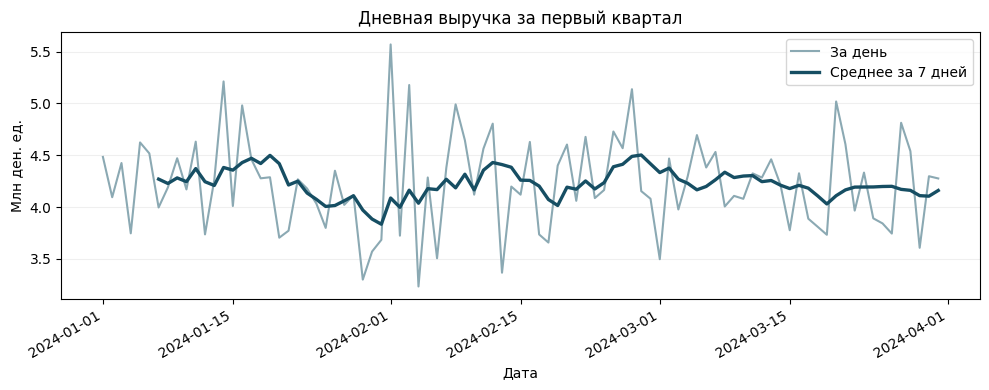

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily["revenue"] / 1_000_000, color="#8ba9b3", label="За день")
ax.plot(daily.index, daily["mean_7d"] / 1_000_000, color="#164e63", linewidth=2.4, label="Среднее за 7 дней")
ax.set(title="Дневная выручка за первый квартал", xlabel="Дата", ylabel="Млн ден. ед.")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

### 4. Период наибольшего роста

Сравниваем соседние непересекающиеся семидневки. Для каждой даты вычитаем из текущего среднего значение семь дней назад и выбираем наибольшую абсолютную прибавку.

In [4]:
change = daily["mean_7d"].diff(7)
end = change.idxmax()
last_week = daily.loc[end - pd.Timedelta(days=13):end - pd.Timedelta(days=7)]
this_week = daily.loc[end - pd.Timedelta(days=6):end]
comparison = []
for week in [last_week, this_week]:
    comparison.append({
        "Начало": week.index.min().date(),
        "Конец": week.index.max().date(),
        "Среднее за день": week["revenue"].mean(),
        "Заказов": week["orders_count"].sum(),
        "Единиц товара": week["units"].sum(),
    })
growth_pct = (this_week["revenue"].mean() / last_week["revenue"].mean() - 1) * 100
print(f"Прирост среднего за день: {change.max():.2f} ({growth_pct:.2f} %)")
pd.DataFrame(comparison).round(2)

Прирост среднего за день: 433310.80 (11.30 %)


,Начало,Конец,Среднее за день,Заказов,Единиц товара
0,2024-01-25,2024-01-31,3834781.77,1065,2634
1,2024-02-01,2024-02-07,4268092.56,1211,3005


### Сравнение месяцев

Продолжительность месяцев различается. Рядом с месячной суммой считаем среднее за календарный день.

In [5]:
monthly = daily.groupby(daily.index.to_period("M")).agg(
    total=("revenue", "sum"),
    daily_mean=("revenue", "mean"),
    days=("revenue", "size"),
    orders_count=("orders_count", "sum"),
)
monthly.round(2)

,total,daily_mean,days,orders_count
order_date,,,,
2024-01,1.293788e+08,4173508.89,31,5000
2024-02,1.253679e+08,4323032.53,29,5000
2024-03,1.297969e+08,4186997.83,31,5000


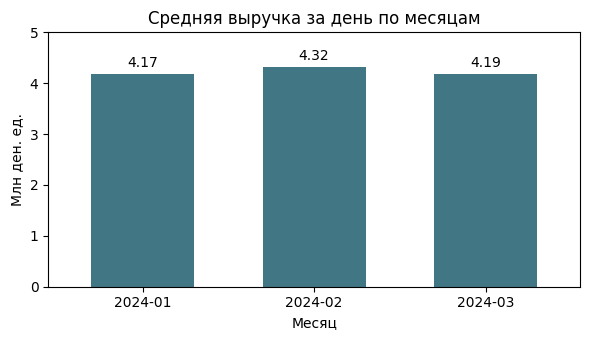

In [6]:
ax = (monthly["daily_mean"] / 1_000_000).plot.bar(
    figsize=(6, 3.5), color="#417784", rot=0, width=0.6
)
ax.set(title="Средняя выручка за день по месяцам", ylabel="Млн ден. ед.", xlabel="Месяц")
ax.set_ylim(0, 5)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.tight_layout()
plt.show()

### Число заказов и дневная выручка

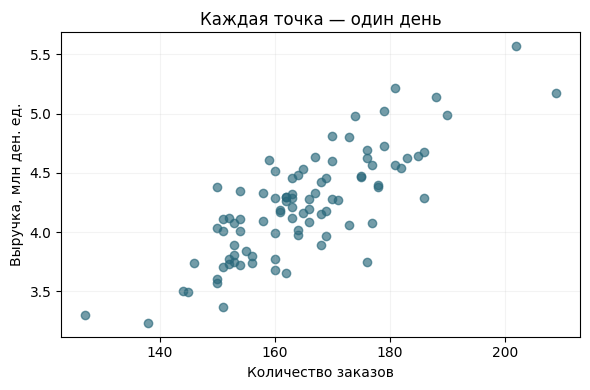

Корреляция: 0.802


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(daily["orders_count"], daily["revenue"] / 1_000_000, alpha=0.65, color="#28677a")
ax.set(title="Каждая точка — один день", xlabel="Количество заказов", ylabel="Выручка, млн ден. ед.")
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()
print("Корреляция:", round(daily["orders_count"].corr(daily["revenue"]), 3))

### Статусы заказов

In [8]:
by_status = orders.groupby("status").agg(orders_count=("order_id", "nunique"), amount=("revenue", "sum"))
by_status["amount_share_pct"] = 100 * by_status["amount"] / by_status["amount"].sum()
by_status = by_status.sort_values("amount", ascending=False)
by_status.round(2)

,orders_count,amount,amount_share_pct
status,,,
paid,12032,3.078290e+08,80.05
cancelled,2212,5.657587e+07,14.71
refunded,756,2.013879e+07,5.24


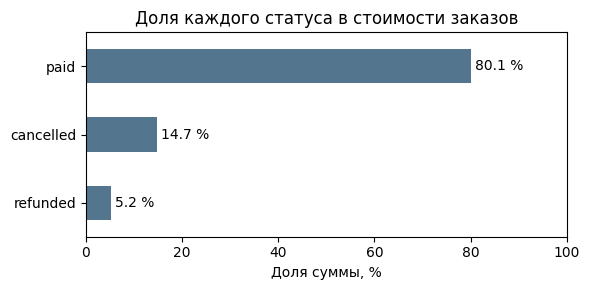

In [9]:
ax = by_status["amount_share_pct"].plot.barh(figsize=(6, 3), color="#53758d")
ax.set(title="Доля каждого статуса в стоимости заказов", xlabel="Доля суммы, %", ylabel="")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.1f %%", padding=3)
plt.tight_layout()
plt.show()

### 5. Аналитический комментарий

1. Самый большой недельный прирост пришёлся на 1–7 февраля относительно 25–31 января. Средняя дневная сумма выросла с 3,83 до 4,27 млн, на 433,31 тыс. (+11,30 %).
2. За эти две недели число заказов изменилось с 1 065 до 1 211, а количество единиц товара в заказах — с 2 634 до 3 005. Покупатели оформили больше заказов, хотя средняя стоимость одного заказа за неделю немного снизилась.
3. Максимум и минимум дневного ряда разделяют всего три дня. За 1 февраля сумма составила 5,57 млн, за 4 февраля — 3,23 млн. Скользящее среднее оставляет видимым общий подъём первой недели февраля, сглаживая перепад между этими датами.
4. Февраль лидирует по средней дневной сумме (4,32 млн), но занимает последнее место по сумме за месяц (125,37 млн). В феврале 29 дней, в январе и марте — по 31. В каждом месячном файле ровно 5 000 заказов.
5. Число заказов и их дневная сумма положительно связаны (коэффициент корреляции 0,802). При одном и том же количестве заказов точки на графике находятся на разной высоте, поскольку различается стоимость покупок.
6. На оплаченные заказы приходится 80,05 % стоимости. Ещё 19,95 % суммы относятся к отменам и возвратам. При оценке поступлений магазину учитывать статусы необходимо.

### Ограничения

Выгрузка охватывает один квартал, поэтому по ней нельзя проверить годовую сезонность. Выручка рассчитана по датам оформления. Даты платежей и возвратов, скидки, рекламные кампании и число посетителей неизвестны. Это ограничивает и оценку денежных поступлений, и объяснение причин недельного роста.